In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [17]:
df = pd.read_csv("credit_risk.csv")
class_counts = df["loan_status"].value_counts(normalize=True) * 100
print(f'Баланс классов:\n0 (Хорошие кредиты): {class_counts[0]:.1f}%\n1 (Дефолты): {class_counts[1]:.1f}%')

X = df.drop("loan_status", axis=1)
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(df.columns)

Баланс классов:
0 (Хорошие кредиты): 78.2%
1 (Дефолты): 21.8%
Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')


In [18]:
numeric_features =['person_age', 'person_income',
                    'person_emp_length', 'loan_amnt',
                    'loan_int_rate', 'loan_percent_income',
                    'cb_person_cred_hist_length']
categorical_features = [ 'person_home_ownership',
                        'loan_intent', 'loan_grade',
                    'cb_person_default_on_file']

numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), 
           ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")), 
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

clf_pipline = Pipeline(
    steps=[("preprocessor", preprocessor), 
           ("classifier", KNeighborsClassifier())]
)

param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform", "distance"],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=clf_pipline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма; {grid_search.best_params_}')




Лучшие параметры алгоритма; {'classifier__n_neighbors': 9, 'classifier__weights': 'distance'}


In [19]:
y_pred = best_model.predict(X_test)

y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Матрица ошибок ---")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - долгов нет, кредит выдан) {conf_matrix[0][0]}")
print(f"Ложноположительные (FP - долгов нет, кредит не выдан) {conf_matrix[0][1]}")
print(f"Ложноотрицательные (FN - долги есть, кредит выдан) {conf_matrix[1][0]}")
print(f"Истинно полжительные (TP - долги есть, кредит не выдан) {conf_matrix[1][1]}")

print("--- Отчет по метрикам ---")
print(classification_report(y_test, y_pred, target_names=["Хороший (0)", "Дефолт (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

--- Матрица ошибок ---
Истинно отрицательные (TN - долгов нет, кредит выдан) 4960
Ложноположительные (FP - долгов нет, кредит не выдан) 135
Ложноотрицательные (FN - долги есть, кредит выдан) 571
Истинно полжительные (TP - долги есть, кредит не выдан) 851
--- Отчет по метрикам ---
              precision    recall  f1-score   support

 Хороший (0)       0.90      0.97      0.93      5095
  Дефолт (1)       0.86      0.60      0.71      1422

    accuracy                           0.89      6517
   macro avg       0.88      0.79      0.82      6517
weighted avg       0.89      0.89      0.88      6517

Площадь под кривой ROC-AUC: 0.8716


In [20]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_error

In [21]:
df_reg = df.dropna(subset=['person_emp_length', 'loan_int_rate']).copy()
X_reg = df_reg[["person_age", "person_income", "person_emp_length", "loan_int_rate"]]
y_reg = df_reg["loan_amnt"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_pipeline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3,30),
    "knn_reg__weights": ["uniform", "distance"]
}
random_search = RandomizedSearchCV(
    estimator=reg_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f"Лучшие параметры алгоритма: {random_search.best_params_}")

Лучшие параметры алгоритма: {'knn_reg__weights': 'distance', 'knn_reg__n_neighbors': np.int64(27)}


In [23]:
y_pred_r = best_reg.predict(X_test_r)
def smape(y_test, y_pred):
    return 100* np.mean(
        2 * np.abs(y_pred-y_test)/(np.abs(y_test)+np.abs(y_pred))
    )
mse = mean_absolute_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE (квадратные $) {mse:.0f}")
print(f"RMSE ($) {rmse:.0f}")
print(f"MAE (Средняя ошибка) {mae:.2f}")
print(f"SMAPE (ошибка в %) {smape_value:.2f}%")

--- Отчет по метрикам регрессии ---
MSE (квадратные $) 3745
RMSE ($) 61
MAE (Средняя ошибка) 3744.91
SMAPE (ошибка в %) 40.71%


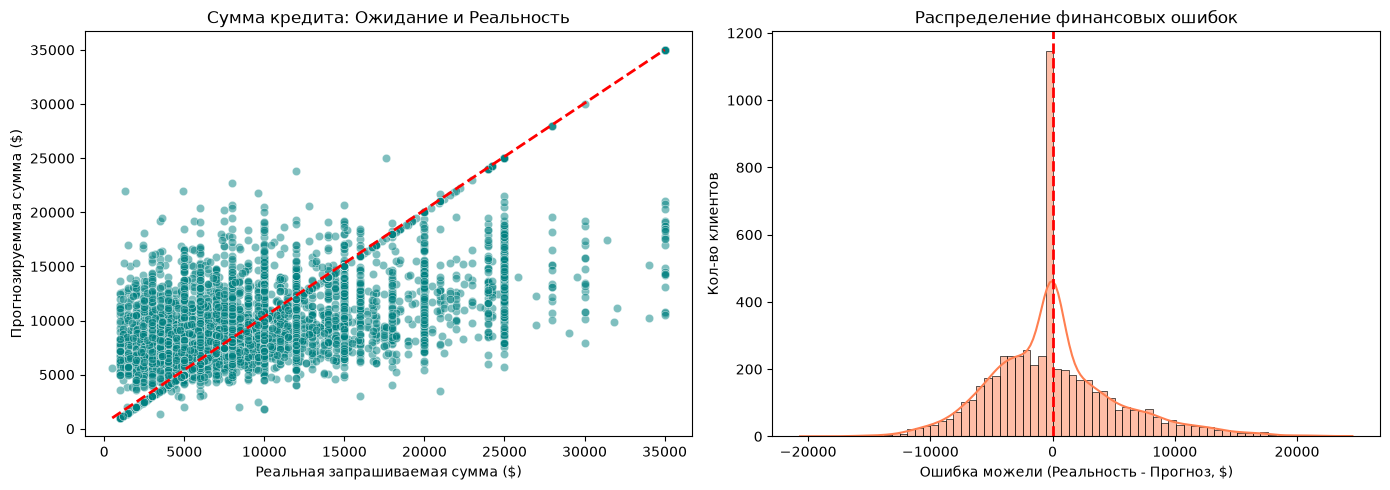

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2,figsize=(14,5))

sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color='teal', ax=axes[0])
axes[0].plot(
    [y_test_r.min(), y_test_r.max()], [y_pred_r.min(), y_pred_r.max()], 'r--', lw=2
)
axes[0].set_title("Сумма кредита: Ожидание и Реальность")
axes[0].set_xlabel("Реальная запрашиваемая сумма ($)")
axes[0].set_ylabel("Прогнозируеммая сумма ($)")

residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle="--", lw=2) # Линия нулевой ошибки
axes[1].set_title("Распределение финансовых ошибок")
axes[1].set_xlabel("Ошибка можели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Кол-во клиентов")

plt.tight_layout()
plt.show()